In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import evaluate_model, plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf

#https://www.geeksforgeeks.org/machine-learning/gated-recurrent-unit-networks/

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense
from tensorflow.keras.optimizers import Adam

I0000 00:00:1795015298.864767 2155530 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795015298.897577 2155530 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795015299.613503 2155530 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


<h1> Import Data

Text(0.5, 0.98, 'All Data')

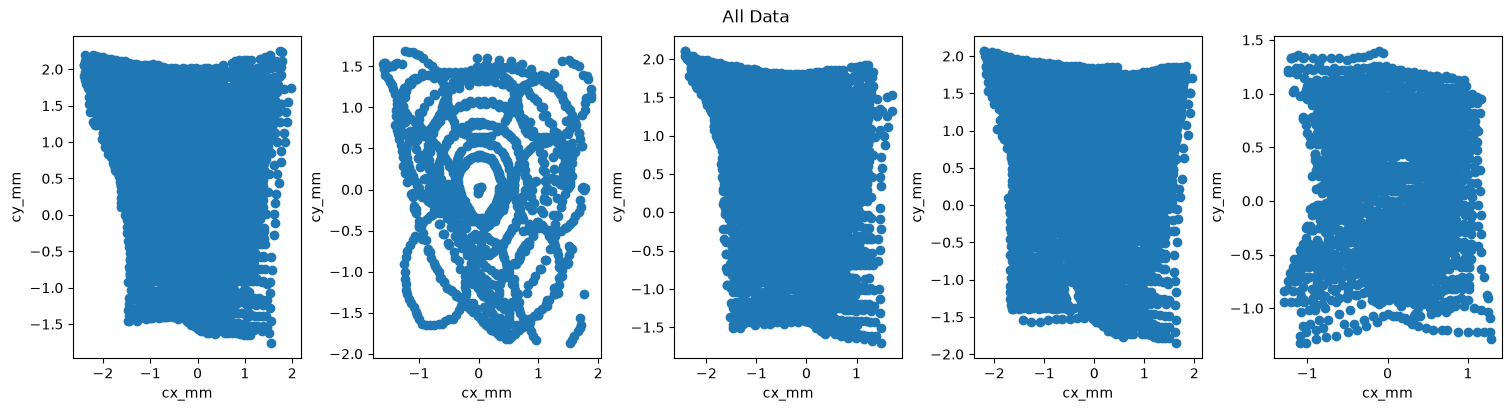

In [3]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_4 = pd.read_csv("processed_data/pred_data.csv", dtype="float32")

#remove nans
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()
data_3 = data_3.dropna()

data_list = [ data_1, data_2, data_3, data_0, data_4]

fig, axs = plt.subplots(1, 5, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
fig.suptitle("All Data")

<h2>Concatenate

In [4]:
all_data = pd.concat(data_list, ignore_index=True)

In [5]:
def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3, constrained_layout=True)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

<h2>Process Data

In [6]:
all_data

,Unnamed: 0,point,time,x,y,x_rb,y_rb,s0,s1,s2,...,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm,m0,m1,m2
0,0.0,0.0,1.272900,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,114.0,432.0,394.0,-1.0,0.0,0.009091,0.000000,NaN,NaN,NaN
1,1.0,1.0,2.764900,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,114.0,434.0,394.0,1.0,0.0,-0.009091,0.000000,NaN,NaN,NaN
2,2.0,0.0,23.054501,1.2,1.2,1.200032,1.200000,6144.0,-8393.0,2249.0,...,-78.0,216.0,202.0,-217.0,-192.0,1.972727,1.745455,NaN,NaN,NaN
3,3.0,1.0,25.128901,1.1,1.2,1.099897,1.200000,6144.0,-7949.0,1805.0,...,-76.0,232.0,204.0,-201.0,-190.0,1.827273,1.727273,NaN,NaN,NaN
4,4.0,2.0,27.203501,1.0,1.2,0.999989,1.200000,6144.0,-7506.0,1362.0,...,-72.0,248.0,208.0,-185.0,-186.0,1.681818,1.690909,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15776,3117.0,622.0,1322.240356,NaN,NaN,-0.831407,-1.073242,-5495.0,6434.0,-939.0,...,266.0,552.0,546.0,98.0,142.0,-0.890909,-1.290909,-5495.0,6434.0,-939.0
15777,3118.0,623.0,1323.956055,NaN,NaN,-0.899855,-1.075391,-5506.0,6743.0,-1237.0,...,270.0,566.0,550.0,112.0,146.0,-1.018182,-1.327273,-5506.0,6743.0,-1237.0
15778,3119.0,624.0,1325.600220,NaN,NaN,-0.960860,-1.079102,-5525.0,7023.0,-1498.0,...,270.0,574.0,550.0,120.0,146.0,-1.090909,-1.327273,-5525.0,7023.0,-1498.0
15779,3120.0,0.0,20.079100,NaN,NaN,0.000000,0.000000,0.0,0.0,0.0,...,114.0,478.0,394.0,24.0,-10.0,-0.218182,0.090909,NaN,NaN,NaN
